# 作业 03：NumPy、Matplotlib 与 pandas

**学号**：20244080326　　**姓名**：罗娜

本作业在独立的 conda 虚拟环境 `conda-hw`（Python 3.11）中完成，包含三个部分：

1. 半圆定律（Wigner 矩阵特征值分布与半圆密度的比较）；
2. Conway 的生命游戏；
3. 使用 pandas DataFrame 读取、修改、扩展并汇总 iris 数据。

In [1]:
import hashlib
import os
import platform
import sys
import uuid

# 修改为自己的学号
STUDENT_ID = 20244080326

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV") or os.path.basename(sys.prefix)
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹]   {MACHINE_FP}")
print(f"[RUN_ID]     {RUN_ID}")
print(f"[Python]     {sys.version.split()[0]}")


[Conda 环境] conda-hw
[学号]       20244080326
[机器指纹]   e8e3a7d29233976b
[RUN_ID]     20244080326-e8e3a7d29233976b
[Python]     3.11.17


## 一、围绕半圆定律

半圆密度为

$$f(x)=\begin{cases}\dfrac{1}{2\pi}\sqrt{4-x^{2}}, & |x|\le 2\\[4pt] 0, & |x|>2\end{cases}$$

`n×n` 对称随机矩阵 `Z` 的上三角元素 `Z_ij (i≤j)` 独立取自 `N(0, 1/n)`，并令 `Z_ji = Z_ij`，即 Wigner 矩阵。

### 1. 半圆密度函数

输入可以是 Python 或 NumPy 的整数、浮点数；开方使用 `numpy.sqrt`。

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 中文字体与负号显示设置
plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False


def wigner_density(x):
    """返回半圆密度在 x 处的值（float）。"""
    if abs(x) <= 2:
        return float(np.sqrt(4 - x ** 2) / (2 * np.pi))
    return 0.0


for x in [0, 1, 2, 2.5, -1, np.int64(1), np.float64(0.5)]:
    print(f"x = {x!r:<10} f(x) = {wigner_density(x):.6f}")

x = 0          f(x) = 0.318310
x = 1          f(x) = 0.275664
x = 2          f(x) = 0.000000
x = 2.5        f(x) = 0.000000
x = -1         f(x) = 0.275664
x = np.int64(1) f(x) = 0.275664
x = np.float64(0.5) f(x) = 0.308202


### 2. 生成 Wigner 矩阵

用 `numpy.triu` 取出上三角（含对角线）后对称化，保证 `Z_ji = Z_ij` 且每个元素只抽取一次。非整数输入抛 `TypeError`，非正数输入抛 `ValueError`。

In [3]:
def generate_wigner(n):
    """生成 n×n 的 Wigner 矩阵，元素方差为 1/n。"""
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)):
        raise TypeError("n 必须是整数")
    if n <= 0:
        raise ValueError("n 必须是正整数")

    a = np.random.normal(0.0, 1.0 / np.sqrt(n), size=(n, n))
    upper = np.triu(a)                                  # 只保留 i <= j 的部分
    z = upper + upper.T - np.diag(np.diag(upper))       # 对称化，对角元只计一次
    return z


z_small = generate_wigner(4)
print("4×4 Wigner 矩阵：")
print(np.round(z_small, 4))
print("是否对称：", np.allclose(z_small, z_small.T))
print("对角线元素方差理论值 1/n =", 1 / 4)

for bad in [3.5, "5", 0, -2]:
    try:
        generate_wigner(bad)
    except Exception as e:
        print(f"输入 {bad!r:<5} -> {type(e).__name__}: {e}")

4×4 Wigner 矩阵：
[[ 0.4276  0.131   1.0803 -0.1321]
 [ 0.131  -0.283   0.0093 -0.5554]
 [ 1.0803  0.0093  0.4978 -0.649 ]
 [-0.1321 -0.5554 -0.649   0.8115]]
是否对称： True
对角线元素方差理论值 1/n = 0.25
输入 3.5   -> TypeError: n 必须是整数
输入 '5'   -> TypeError: n 必须是整数
输入 0     -> ValueError: n 必须是正整数
输入 -2    -> ValueError: n 必须是正整数


### 3. 特征值

`numpy.linalg.eigvalsh` 专门求解实对称矩阵的特征值，返回结果本身按非递减顺序排列。

In [4]:
def get_spectrum(matrix):
    """返回矩阵全部特征值（非递减）的 NumPy 数组。"""
    return np.linalg.eigvalsh(np.asarray(matrix))


print("4×4 矩阵的特征值：", np.round(get_spectrum(z_small), 4))
print("是否非递减：", np.all(np.diff(get_spectrum(z_small)) >= 0))

4×4 矩阵的特征值： [-0.8303 -0.365   0.7329  1.9164]
是否非递减： True


### 4. 特征值直方图与半圆密度

对 `n = 100, 200, 500, 1000`，把 `n×n` Wigner 矩阵的特征值画成蓝色标准化直方图（`density=True`），并叠加红色半圆密度曲线。

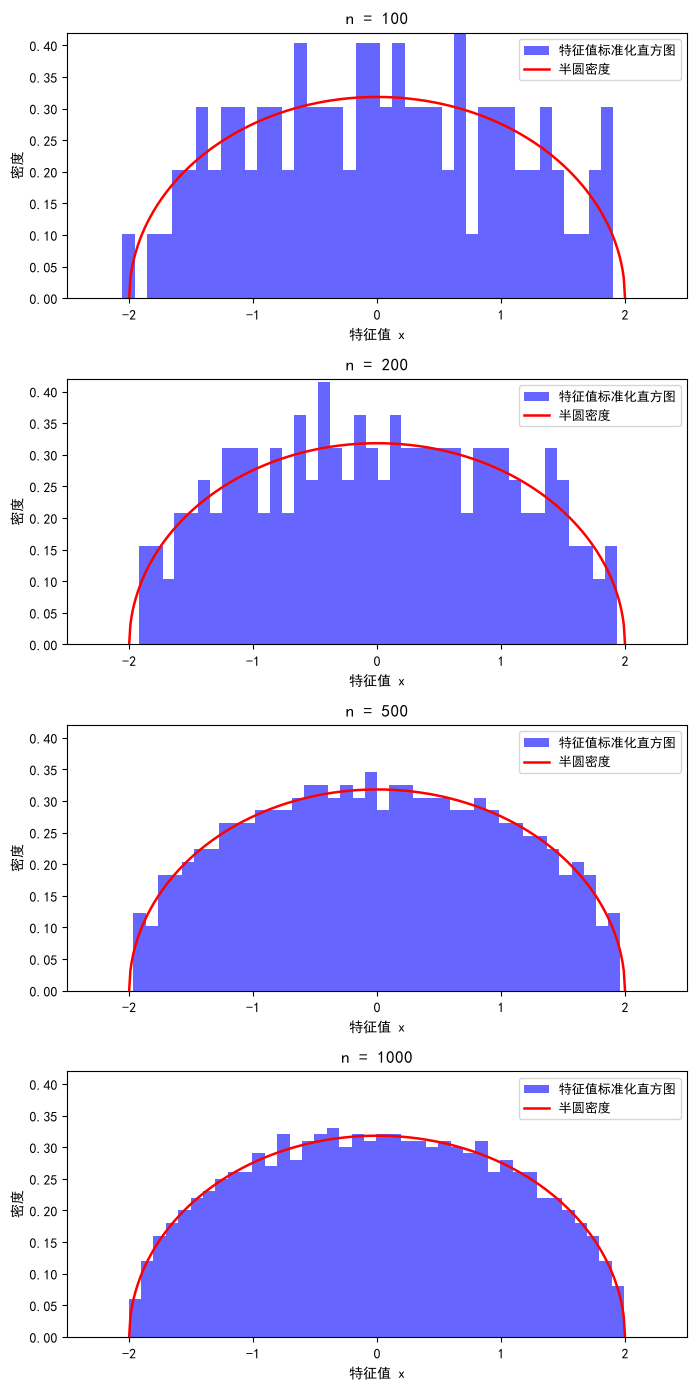

In [5]:
np.random.seed(42)

ns = [100, 200, 500, 1000]
xs = np.linspace(-2, 2, 400)
density = np.vectorize(wigner_density)(xs)

fig, axes = plt.subplots(4, 1, figsize=(7, 14))
for ax, n in zip(axes, ns):
    eigvals = get_spectrum(generate_wigner(n))
    ax.hist(eigvals, bins=40, density=True, color="blue", alpha=0.6,
            label="特征值标准化直方图")
    ax.plot(xs, density, color="red", linewidth=1.8, label="半圆密度")
    ax.set_title(f"n = {n}")
    ax.set_xlabel("特征值 x")
    ax.set_ylabel("密度")
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(0, 0.42)
    ax.legend(loc="upper right", fontsize=9)

plt.tight_layout()
plt.show()

**结论**

- `n = 100` 时直方图波动明显，与半圆曲线偏差较大；
- `n = 200` 时整体形状已接近半圆，但峰值和边缘仍有可见起伏；
- `n = 500` 时直方图与红色曲线的吻合程度已较好；
- `n = 1000` 时两者几乎完全重合。

因此 `n` 大约达到 **500** 时，半圆密度就能较好地拟合特征值分布（`n = 1000` 更好），这与随机矩阵理论中 `n → ∞` 的极限结论一致。

## 二、Conway 的生命游戏

棋盘用 `m×n` 的 NumPy 二维数组表示（活细胞 1、死细胞 0），采用环绕边界，每一步同时更新所有细胞。

### 1. 有效性检查

要求：输入是 `numpy.ndarray`、二维、元素只取 0 或 1，返回 Python 布尔值。

In [6]:
def is_valid_board(board):
    """判断 board 是否是有效的生命游戏棋盘，返回 Python bool。"""
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    return bool(np.all((board == 0) | (board == 1)))


tests = [
    np.array([[0, 1], [1, 0]]),
    np.array([[0, 1], [1, 2]]),
    np.array([0, 1, 0]),
    [[0, 1], [1, 0]],
]
for t in tests:
    print(f"{type(t).__name__:<10} -> {is_valid_board(t)}")

ndarray    -> True
ndarray    -> False
ndarray    -> False
list       -> False


### 2. 推进一步

用 8 个方向的 `numpy.roll` 平移叠加得到每个细胞的活邻居数，`roll` 的环绕特性正好实现环绕边界。更新规则用布尔掩码一次性作用在**原棋盘**上，从而保证同步更新。

In [7]:
def gol_step(board):
    """返回生命游戏棋盘的下一个状态。"""
    if not is_valid_board(board):
        raise ValueError("board 必须是元素仅为 0/1 的二维 NumPy 数组")

    m, n = board.shape
    neighbors = np.zeros((m, n), dtype=int)
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            if di == 0 and dj == 0:
                continue
            neighbors += np.roll(np.roll(board, di, axis=0), dj, axis=1)

    next_board = np.zeros((m, n), dtype=int)
    # 活细胞：邻居数为 2 或 3 时存活
    next_board[(board == 1) & ((neighbors == 2) | (neighbors == 3))] = 1
    # 死细胞：邻居数恰好为 3 时复活
    next_board[(board == 0) & (neighbors == 3)] = 1
    return next_board


glider = np.zeros((6, 6), dtype=int)
glider[1, 2] = glider[2, 3] = 1
glider[3, 1] = glider[3, 2] = glider[3, 3] = 1

print("初始棋盘：")
print(glider)
for step in range(4):
    glider = gol_step(glider)
print("\n4 步之后的棋盘（滑翔机整体向右下平移一格）：")
print(glider)

for bad in [np.array([[0, 1], [1, 2]]), np.array([0, 1, 0]), "0101"]:
    try:
        gol_step(bad)
    except Exception as e:
        print(f"{type(e).__name__}: {e}")

初始棋盘：
[[0 0 0 0 0 0]
 [0 0 1 0 0 0]
 [0 0 0 1 0 0]
 [0 1 1 1 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]]

4 步之后的棋盘（滑翔机整体向右下平移一格）：
[[0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 1 0 0]
 [0 0 0 0 1 0]
 [0 0 1 1 1 0]
 [0 0 0 0 0 0]]
ValueError: board 必须是元素仅为 0/1 的二维 NumPy 数组
ValueError: board 必须是元素仅为 0/1 的二维 NumPy 数组
ValueError: board 必须是元素仅为 0/1 的二维 NumPy 数组


### 3. 绘制棋盘

活细胞黑色、死细胞白色；不显示网格线、轴标签和刻度。用 `ListedColormap(["white", "black"])` 把 0/1 映射为白/黑。

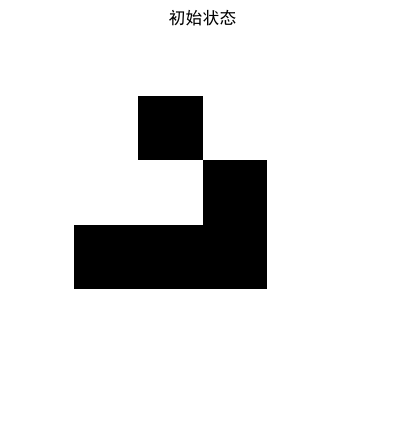

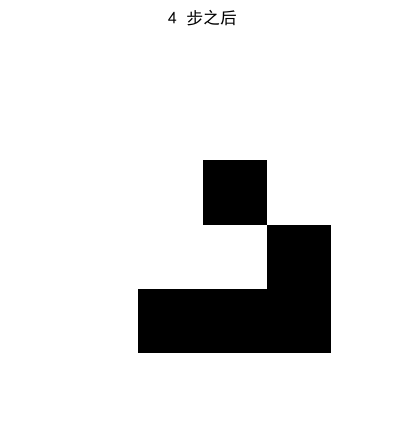

In [8]:
from matplotlib.colors import ListedColormap


def draw_gol_board(board):
    """把棋盘画成 m×n 个方格：活细胞黑色，死细胞白色。"""
    cmap = ListedColormap(["white", "black"])
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(board, cmap=cmap, vmin=0, vmax=1, interpolation="nearest")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    ax.set_frame_on(False)


start = np.zeros((6, 6), dtype=int)
start[1, 2] = start[2, 3] = 1
start[3, 1] = start[3, 2] = start[3, 3] = 1

board = start.copy()
draw_gol_board(board)
plt.title("初始状态")
plt.show()

for _ in range(4):
    board = gol_step(board)
draw_gol_board(board)
plt.title("4 步之后")
plt.show()

## 三、使用 pandas DataFrame

### 1. 读取本地 Iris.csv

数据文件为 `../作业文件/Iris.csv`，第一行是列标题。读取后检查数据点个数、列名、数据类型与花卉种类。

In [9]:
from pathlib import Path
import pandas as pd

iris_path = Path("../作业文件/Iris.csv")
df = pd.read_csv(iris_path)

print("读取文件：", iris_path)
print("数据点个数：", len(df))
print("形状 (行, 列)：", df.shape)
print("列名：", df.columns.tolist())
print("\n每列数据类型：")
print(df.dtypes)
print("\n花卉种类及数量：")
print(df["Species"].value_counts())

读取文件： ..\作业文件\Iris.csv
数据点个数： 150
形状 (行, 列)： (150, 6)
列名： ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']

每列数据类型：
Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species              str
dtype: object

花卉种类及数量：
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


回答：

- 数据集共有 **150** 个数据点；
- 列名共 6 个：`Id`（记录编号）、`SepalLengthCm`（萼片长度）、`SepalWidthCm`（萼片宽度）、`PetalLengthCm`（花瓣长度）、`PetalWidthCm`（花瓣宽度）、`Species`（花卉种类）；
- `Id` 为 `int64`，四项测量均为 `float64`，`Species` 为字符串；
- 数据包含 **3** 种花卉：`Iris-setosa`、`Iris-versicolor`、`Iris-virginica`，各 50 条。

### 2. 修正第 35、38 个数据行

不计列标题时，第 35、38 行对应默认行索引 **34、37**。本地文件比题目中的五列形式多一个 `Id` 列，因此保留编号不变，只覆盖四项测量和种类。

本地种类写作 `Iris-setosa`，与题目中的 `setosa` 表示同一种花；保留原文件的命名方式，避免同列出现两套类别名称。

In [10]:
columns_to_fix = [
    "SepalLengthCm", "SepalWidthCm", "PetalLengthCm",
    "PetalWidthCm", "Species"
]

print("修改前：")
print(df.loc[[34, 37], ["Id"] + columns_to_fix])

df.loc[34, columns_to_fix] = [4.9, 3.1, 1.5, 0.2, "Iris-setosa"]
df.loc[37, columns_to_fix] = [4.9, 3.6, 1.4, 0.1, "Iris-setosa"]

print("\n修改后：")
print(df.loc[[34, 37], ["Id"] + columns_to_fix])

assert df.loc[34, columns_to_fix].tolist() == [4.9, 3.1, 1.5, 0.2, "Iris-setosa"]
assert df.loc[37, columns_to_fix].tolist() == [4.9, 3.6, 1.4, 0.1, "Iris-setosa"]
assert df.loc[34, "Id"] == 35 and df.loc[37, "Id"] == 38

修改前：
    Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
34  35            4.9           3.1            1.5           0.1  Iris-setosa
37  38            4.9           3.1            1.5           0.1  Iris-setosa

修改后：
    Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
34  35            4.9           3.1            1.5           0.2  Iris-setosa
37  38            4.9           3.6            1.4           0.1  Iris-setosa


### 3. 添加两个新特征

- `Petal.Ratio = PetalLengthCm / PetalWidthCm`
- `Sepal.Ratio = SepalLengthCm / SepalWidthCm`

In [11]:
df["Petal.Ratio"] = df["PetalLengthCm"] / df["PetalWidthCm"]
df["Sepal.Ratio"] = df["SepalLengthCm"] / df["SepalWidthCm"]

print(df.head())
print("\n新增列的统计描述：")
print(df[["Petal.Ratio", "Sepal.Ratio"]].describe())

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species  \
0   1            5.1           3.5            1.4           0.2  Iris-setosa   
1   2            4.9           3.0            1.4           0.2  Iris-setosa   
2   3            4.7           3.2            1.3           0.2  Iris-setosa   
3   4            4.6           3.1            1.5           0.2  Iris-setosa   
4   5            5.0           3.6            1.4           0.2  Iris-setosa   

   Petal.Ratio  Sepal.Ratio  
0          7.0     1.457143  
1          7.0     1.633333  
2          6.5     1.468750  
3          7.5     1.483871  
4          7.0     1.388889  

新增列的统计描述：
       Petal.Ratio  Sepal.Ratio
count   150.000000   150.000000
mean      4.310500     1.953681
std       2.489648     0.400480
min       2.125000     1.268293
25%       2.802381     1.546188
50%       3.300000     2.032292
75%       4.666667     2.224910
max      15.000000     2.961538


### 4. 保存为 iris_corrected.csv

In [12]:
output_path = Path("iris_corrected.csv")
df.to_csv(output_path, index=False)
print("已保存：", output_path.resolve())
print("保存后的形状：", df.shape)

已保存： D:\Python数据分析\Python文件\iris_corrected.csv
保存后的形状： (150, 8)


### 5. 按花卉种类分组汇总

用一次 `groupby().agg()` 同时得到 `Petal.Ratio` 与 `Sepal.Ratio` 的平均值、中位数、最小值、最大值和标准差。

In [13]:
summary = (
    df.groupby("Species")[["Petal.Ratio", "Sepal.Ratio"]]
      .agg(["mean", "median", "min", "max", "std"])
)
print(summary.round(4))

                Petal.Ratio                               Sepal.Ratio          \
                       mean  median     min   max     std        mean  median   
Species                                                                         
Iris-setosa          6.9080  7.0000  2.6667  15.0  2.8545      1.4702  1.4631   
Iris-versicolor      3.2428  3.2404  2.6667   4.1  0.3125      2.1604  2.1613   
Iris-virginica       2.7807  2.6667  2.1250   4.0  0.4074      2.2305  2.1695   

                                         
                    min     max     std  
Species                                  
Iris-setosa      1.2683  1.9565  0.1187  
Iris-versicolor  1.7647  2.8182  0.2287  
Iris-virginica   1.8235  2.9615  0.2470  


**结果解读**

- `Iris-setosa` 的 `Petal.Ratio` 平均值最大（约 6.91），但标准差也最大（约 2.85）：其花瓣宽度很小，宽度变化会被比值放大；
- `Iris-versicolor` 与 `Iris-virginica` 的 `Petal.Ratio` 均值约为 3.24 和 2.78，均明显小于 `Iris-setosa`；
- 三个物种的 `Sepal.Ratio` 均值约为 1.47、2.16、2.23，后两者较接近。